In [24]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam 

# from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
# load the data as a pandas dataframe
# data = load_breast_cancer()
# df = pd.DataFrame(data.data , columns=data.feature_names)
# df['target'] = data.target

In [18]:
# load the breast cancer dataset from csv file
df = pd.read_csv("./datasets/breast_cancer.csv")
print(df["target"].value_counts())

target
1    357
0    212
Name: count, dtype: int64


In [19]:
print(f"Size : {df.size}\nShape : {df.shape}")
print(df.tail())

Size : 17639
Shape : (569, 31)
     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
564        21.56         22.39          142.00     1479.0          0.11100   
565        20.13         28.25          131.20     1261.0          0.09780   
566        16.60         28.08          108.30      858.1          0.08455   
567        20.60         29.33          140.10     1265.0          0.11780   
568         7.76         24.54           47.92      181.0          0.05263   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
564           0.11590         0.24390              0.13890         0.1726   
565           0.10340         0.14400              0.09791         0.1752   
566           0.10230         0.09251              0.05302         0.1590   
567           0.27700         0.35140              0.15200         0.2397   
568           0.04362         0.00000              0.00000         0.1587   

     mean fractal dimension  ...  wor

In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [21]:
X = df.drop('target',axis=1)
y = df['target']

In [22]:
# create train, test and validation sets
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size=0.1 , random_state=42 , stratify=y)
X_train , X_val , y_train , y_val = train_test_split(X_train , y_train , test_size=0.1 , random_state=42 , stratify=y_train)
print(f"X_train : {X_train.shape}")
print(f"X_validation : {X_val.shape}")
print(f"X_test : {X_test.shape}")

X_train : (460, 30)
X_validation : (52, 30)
X_test : (57, 30)


In [23]:
# Standardize the entire dataset
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

## *01> Perceptron*

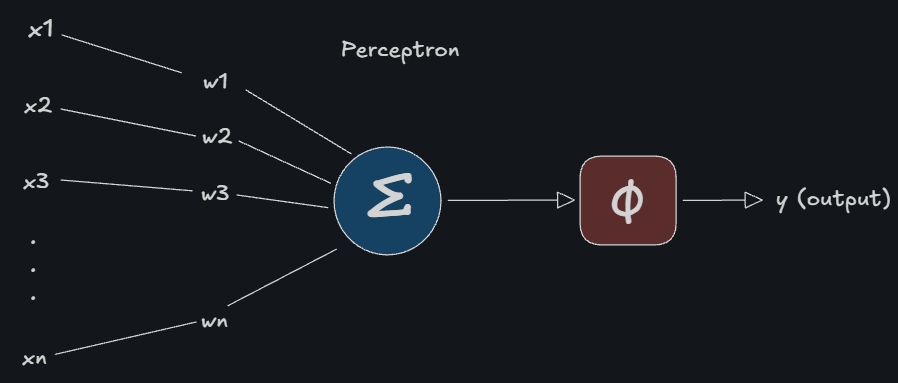

In [32]:
# Create a single perceptron 
model_01 = Sequential([
    Dense(1 , activation="sigmoid")
])

# select hyperparameters
model_01.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy", # binary cross entropy for binary classn, categorical for multi class + onehotencoded, sparse cat for multi class + ordinal encoding
    metrics=["accuracy"]
)

# train the perceptron
history_01 = model_01.fit(
    X_train, y_train,
    validation_data=(X_val , y_val),
    epochs = 15,
    batch_size=32
)

test_loss_01 , test_accuracy_01 = model_01.evaluate(X_test , y_test)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.6848 - loss: 0.6214 - val_accuracy: 0.7692 - val_loss: 0.5786
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7283 - loss: 0.5562 - val_accuracy: 0.7885 - val_loss: 0.5259
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7674 - loss: 0.5027 - val_accuracy: 0.8077 - val_loss: 0.4808
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8043 - loss: 0.4577 - val_accuracy: 0.8077 - val_loss: 0.4429
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8174 - loss: 0.4202 - val_accuracy: 0.8269 - val_loss: 0.4106
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8348 - loss: 0.3883 - val_accuracy: 0.8462 - val_loss: 0.3831
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8543 - loss: 0.3610 - val_accuracy: 0.8654 - val_loss: 0.3593
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8739 - loss: 0.3376 - val_accuracy: 0.8654 - val_loss

In [34]:
print(f"Test Accuracy for Single Perceptron : {test_accuracy_01*100:.2f}%")

Test Accuracy for Single Perceptron : 91.23%


## *02> MLP*

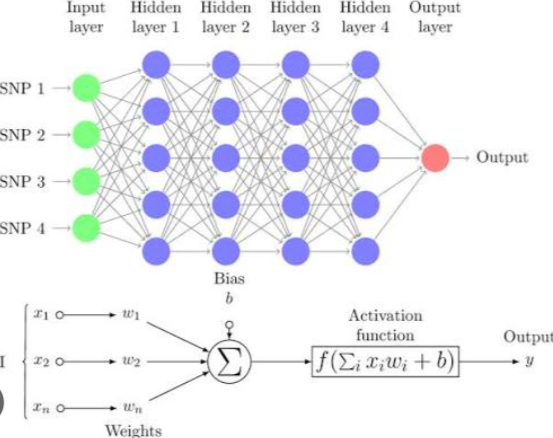

In [35]:
# Create a MLP 
model_02 = Sequential([
    Dense(16 , activation="relu"),
    Dense(8 , activation="relu"),
    Dense(1 , activation="sigmoid")
])

# select hyperparameters
model_02.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# train the perceptron
history_02 = model_02.fit(
    X_train, y_train,
    validation_data=(X_val , y_val),
    epochs = 15,
    batch_size=32
)

test_loss_02 , test_accuracy_02 = model_02.evaluate(X_test , y_test)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.3348 - loss: 0.8252 - val_accuracy: 0.5769 - val_loss: 0.6695
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7217 - loss: 0.6106 - val_accuracy: 0.8269 - val_loss: 0.5247
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8804 - loss: 0.4789 - val_accuracy: 0.9423 - val_loss: 0.4092
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9239 - loss: 0.3809 - val_accuracy: 0.9423 - val_loss: 0.3237
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9304 - loss: 0.3107 - val_accuracy: 0.9423 - val_loss: 0.2639
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9326 - loss: 0.2592 - val_accuracy: 0.9423 - val_loss: 0.2208
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9413 - loss: 0.2206 - val_accuracy: 0.9423 - val_loss: 0.1883
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9478 - loss: 0.1915 - val_accuracy: 0.9423 - val_loss

In [36]:
print(f"Test Accuracy for MLP : {test_accuracy_02*100:.2f}%")

Test Accuracy for MLP : 94.74%


## *03> Visualization(Plots)*

In [37]:
def plot_history(history, title):
    print(title)
    plt.figure(figsize=(10, 4))

    # Loss
    plt.subplot(1, 2, 1)
    plt.plot(history.history["loss"])
    plt.plot(history.history["val_loss"])
    plt.title("Loss")
    plt.legend(["Train", "Validation"])

    # Accuracy
    plt.subplot(1, 2, 2)
    plt.plot(history.history["accuracy"])
    plt.plot(history.history["val_accuracy"])
    plt.title("Accuracy")
    plt.legend(["Train", "Validation"])

    
    plt.show()

Perceptron


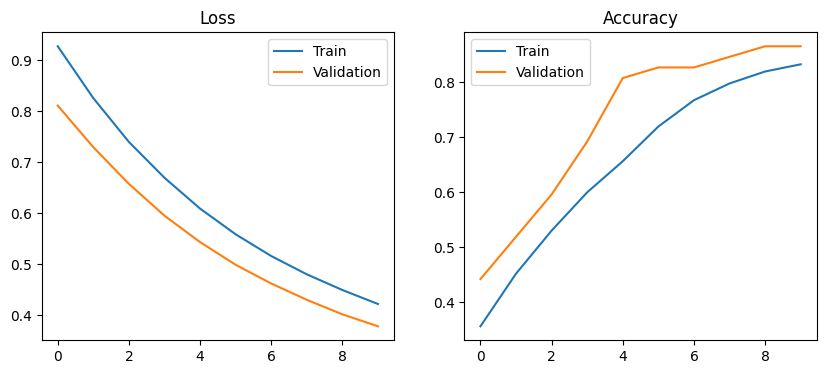

In [31]:
plot_history(history_01,"Perceptron")

MLP


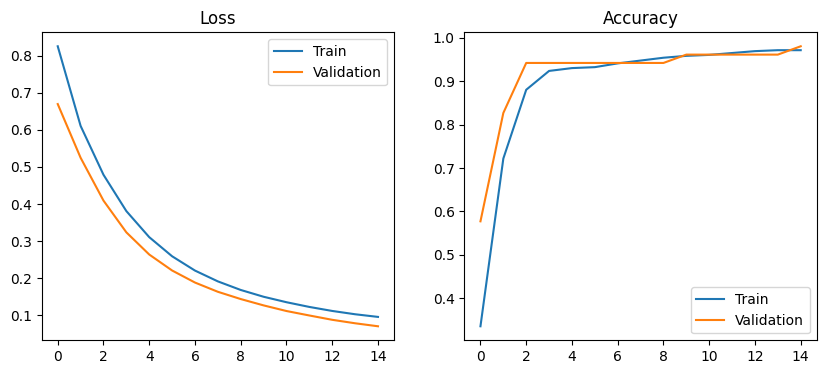

In [38]:
plot_history(history_02, "MLP")

In [39]:
sample = scaler.transform(X.iloc[[568]])

def predict(model, X):
    prediction = model.predict(X)
    return (prediction > 0.5).astype(int)

In [40]:
predict(model_01 , sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 108ms/step


array([[1]])

In [41]:
predict(model_02 , sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step


array([[1]])

In [42]:
print(df.iloc[[568]])

     mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
568         7.76         24.54           47.92      181.0          0.05263   

     mean compactness  mean concavity  mean concave points  mean symmetry  \
568           0.04362             0.0                  0.0         0.1587   

     mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
568                 0.05884  ...          30.37            59.16       268.6   

     worst smoothness  worst compactness  worst concavity  \
568           0.08996            0.06444              0.0   

     worst concave points  worst symmetry  worst fractal dimension  target  
568                   0.0          0.2871                  0.07039       1  

[1 rows x 31 columns]
